In [1]:
# Dependencies are declared in pyproject.toml and installed once with ./init.sh
import sys
from importlib.metadata import PackageNotFoundError, version

print('Python', sys.version.split()[0])
for package in ('Cython', 'setuptools', 'matplotlib'):
    try:
        print(package, version(package))
    except PackageNotFoundError:
        raise RuntimeError(f'{package} is missing: run ./init.sh, then restart the kernel') from None

Python 3.14.4
Cython 3.3.0
setuptools 84.0.0
matplotlib 3.11.2


In [2]:
# Requires both cython and setuptools on Python 3.12+
%load_ext cython

In [3]:
import math
def primes_count(from_n, to_m):
    assert(2 <= from_n and from_n <= to_m)
    sieve = [1] * (math.isqrt(to_m) + 1)
    sieve[0] = 0
    sieve[1] = 0
    for i in range(2, math.isqrt(len(sieve))):
        if not sieve[i]:
            continue;
        #j = 2 * i
        #while j < len(sieve):
        for j in range(2 * i, len(sieve), i):
            sieve[j] = 0
            #j += i
    primes = [ i for i in range(len(sieve)) if sieve[i] ]
    #print(primes)

    larger_primes = []
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.append(i)
    #print(larger_primes)
    return len(larger_primes)

print(primes_count(2, 1000))
print(primes_count(907, 997))
print(primes_count(10**10-999, 10**10))

168
14
41


In [4]:
%%cython

import math
def primes_count_cy0(from_n, to_m):
    assert(2 <= from_n and from_n <= to_m)
    sieve = [1] * (math.isqrt(to_m) + 1)
    sieve[0] = 0
    sieve[1] = 0
    for i in range(2, math.isqrt(len(sieve))):
        if not sieve[i]:
            continue;
        #j = 2 * i
        #while j < len(sieve):
        for j in range(2 * i, len(sieve), i):
            sieve[j] = 0
            #j += i
    primes = [ i for i in range(len(sieve)) if sieve[i] ]
    #print(primes)

    larger_primes = []
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.append(i)
    #print(larger_primes)
    return len(larger_primes)

print(primes_count_cy0(2, 1000))
print(primes_count_cy0(907, 997))
print(primes_count_cy0(10**10-999, 10**10))

168
14
41


In [5]:
%%cython --compile-args=-O3

# cython: boundscheck=False, wraparound=False, cdivision=True
import cython
import math

def primes_count_cy1(from_n: cython.ulonglong, to_m: cython.ulonglong):
    i: cython.ulonglong
    j: cython.ulonglong
    assert(2 <= from_n and from_n <= to_m)
    sieve: list[cython.uchar] = [1] * (math.isqrt(to_m) + 1)
    sieve[0] = 0
    sieve[1] = 0
    for i in range(2, math.isqrt(len(sieve))):
        if not sieve[i]:
            continue;
        #for j in range(2 * i, len(sieve), i):
        j = 2 * i
        while j < len(sieve):
            sieve[j] = 0
            j += i
    primes: list[cython.ulonglong] = [ i for i in range(len(sieve)) if sieve[i] ]
    #print(primes)

    larger_primes: list[ulonglong] = []
    f: cython.ulonglong
    p: cython.ulonglong
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.append(i)
    #print(larger_primes)
    return len(larger_primes)

print(primes_count_cy1(2, 1000))
print(primes_count_cy1(907, 997))
print(primes_count_cy1(10**10-999, 10**10))

168
14
41


In [6]:
%%cython

# distutils: language=c++
# distutils: extra_compile_args = -O3 -std=c++20 -funroll-loops
# cython: language_level=3
import cython
from libcpp.vector cimport vector
import math

@cython.cdivision(True)
cdef unsigned long long primes_count_impl(unsigned long long from_n, unsigned long long to_m):
    cdef unsigned long long i, j, f, p
    cdef vector[unsigned char] sieve
    
    assert(2 <= from_n and from_n <= to_m)
    sieve.reserve(math.isqrt(to_m) + 1)
    sieve.assign(math.isqrt(to_m) + 1, 1)

    sieve[0] = 0
    sieve[1] = 0
    cdef int primes_found = 0
    for i in range(2, math.isqrt(sieve.size())):
        if not sieve[i]:
            continue;
        primes_found += 1
        #for j in range(2 * i, sieve.size(), i): # Cython does not optimize range() as a C loop with non-constant arguments
        j = 2 * i
        while j < sieve.size():
            sieve[j] = 0
            j += i

    cdef vector[unsigned long long] primes
    primes.reserve(primes_found)
    for i in range(sieve.size()):
        if sieve[i]:
            primes.push_back(i)
    #print(primes)

    cdef vector[unsigned long long] larger_primes
    larger_primes.reserve(primes.size()) # gross estimate to minimize future reallocations
    for i in range(from_n, to_m + 1):
        f = i
        for p in primes:
            if 0 == i % p:
                f = p
                break;
        if f == i:
            larger_primes.push_back(i)
    #print(larger_primes)
    return larger_primes.size()

def primes_count_cy2(from_n: cython.ulonglong, to_m: cython.ulonglong):
    return primes_count_impl(from_n, to_m)

print()
print(primes_count_cy2(2, 1000))
print(primes_count_cy2(907, 997))
print(primes_count_cy2(10**10-999, 10**10))


168
14
41


Milliseconds per call
                   range            Python      Cython as is  Cython annotated       Cython cdef
   [10**4 - 1000, 10**4]             0.138             0.069             0.013             0.006
   [10**5 - 1000, 10**5]             0.219             0.100             0.019             0.009
   [10**6 - 1000, 10**6]             0.427             0.257             0.034             0.017
   [10**7 - 1000, 10**7]             0.860             0.601             0.068             0.028
   [10**8 - 1000, 10**8]             2.053             1.662             0.170             0.070
   [10**9 - 1000, 10**9]             5.032             4.507             0.487             0.169
 [10**10 - 1000, 10**10]            14.994            14.290             1.422             0.501
 [10**11 - 1000, 10**11]            41.937            41.477             4.100             1.446
 [10**12 - 1000, 10**12]           116.936           123.393            12.034             3.981

Speedup

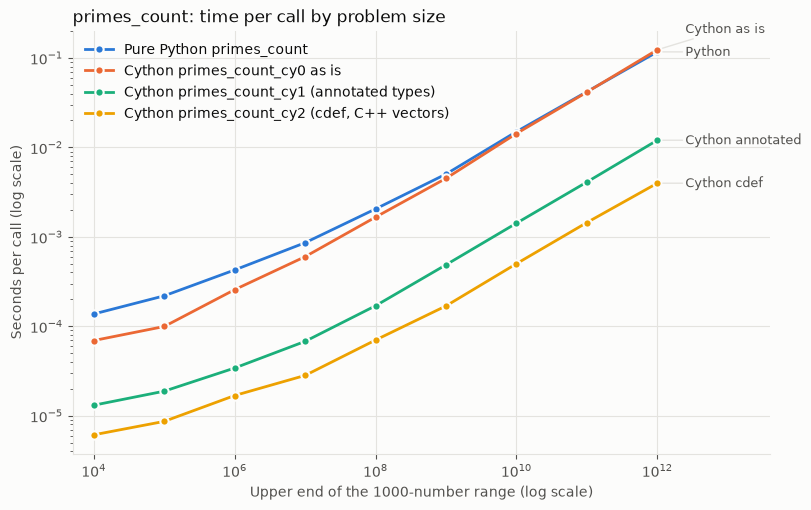

In [7]:
# Time per call of all four primes_count versions for growing problem sizes:
# a table in the console, then a log-log plot
from timeit import timeit
import matplotlib.pyplot as plt

candidates = [  # (legend label, short label, function); colors follow this order
    ('Pure Python primes_count', 'Python', primes_count),
    ('Cython primes_count_cy0 as is', 'Cython as is', primes_count_cy0),
    ('Cython primes_count_cy1 (annotated types)', 'Cython annotated', primes_count_cy1),
    ('Cython primes_count_cy2 (cdef, C++ vectors)', 'Cython cdef', primes_count_cy2),
]
exponents = range(4, 13)  # each call counts primes in [10**k - 1000, 10**k]
number = 10  # calls per measurement

seconds_per_call = {}
for label, short, function in candidates:
    seconds_per_call[short] = [timeit(lambda: function(10**k - 1000, 10**k), number=number) / number
                               for k in exponents]

print('Milliseconds per call')
print(f'{"range":>24s}' + ''.join(f'{short:>18s}' for _, short, _ in candidates))
for i, k in enumerate(exponents):
    print(f'{f"[10**{k} - 1000, 10**{k}]":>24s}'
          + ''.join(f'{seconds_per_call[short][i] * 1e3:18.3f}' for _, short, _ in candidates))

for exp in (0, -1):
    python_time = seconds_per_call['Python'][exp]
    print(f'\nSpeedup over pure Python at 10**{exponents[exp]}: '
          + ', '.join(f'{short} x{python_time / seconds_per_call[short][exp]:.2f}' for _, short, _ in candidates[1:]))

# Categorical slots 1-4 of the reference palette, validated for adjacent lines on a light surface
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
surface, text_primary, text_secondary, grid = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

sizes = [10**k for k in exponents]
fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=surface)
ax.set_facecolor(surface)
for (label, short, _), color in zip(candidates, colors):
    ax.plot(sizes, seconds_per_call[short], color=color, linewidth=2, marker='o', markersize=6,
            markeredgecolor=surface, markeredgewidth=1.5, label=label)

# Direct labels at the line ends, nudged apart where lines end close together
label_y = []
for value, short in sorted((seconds_per_call[short][-1], short) for _, short, _ in candidates):
    y = max(value, label_y[-1] * 1.8) if label_y else value
    label_y.append(y)
    ax.annotate(short, xy=(sizes[-1], value), xytext=(sizes[-1] * 2.5, y), color=text_secondary, fontsize=9,
                va='center', arrowprops=dict(arrowstyle='-', color=grid, linewidth=1, shrinkA=0, shrinkB=4))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(sizes[0] / 2, sizes[-1] * 40)
ax.set_xlabel('Upper end of the 1000-number range (log scale)', color=text_secondary)
ax.set_ylabel('Seconds per call (log scale)', color=text_secondary)
ax.set_title('primes_count: time per call by problem size', color=text_primary, loc='left')
ax.grid(True, which='major', color=grid, linewidth=0.8)
ax.tick_params(colors=text_secondary, which='both')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color(grid)
ax.legend(loc='upper left', frameon=False, labelcolor=text_primary)
plt.show()

In [8]:
from ctypes import *
import random

libc = CDLL("libc.so.6")

# void qsort( void *ptr, std::size_t count, std::size_t size, /* c-compare-pred */* comp );
libc.qsort.argtypes = [c_void_p, c_size_t, c_size_t, c_void_p]
libc.qsort.restype = None

# int cmp(const void *a, const void *b);
@CFUNCTYPE(c_int, POINTER(c_double), POINTER(c_double))
def compare_doubles_py(left, right):
    return -1 if left[0] < right[0] else (1 if right[0] < left[0] else 0)

def qsort_doubles_py(d):
    libc.qsort(d, len(d), sizeof(c_double), compare_doubles_py)

def prepare_shuffled_doubles(n = 10):
    doubles = [float(i) for i in range(n, 0, -1)]
    random.shuffle(doubles)
    return doubles

n = 10
double_array = c_double * n
d = double_array(*prepare_shuffled_doubles(n))
print(' '.join(str(x) for x in d))

qsort_doubles_py(d)
print(' '.join(str(x) for x in d))

5.0 3.0 9.0 6.0 7.0 8.0 4.0 2.0 1.0 10.0
1.0 2.0 3.0 4.0 5.0 6.0 7.0 8.0 9.0 10.0


In [9]:
%%cython

import cython
from ctypes import *

libc = CDLL("libc.so.6")

# void qsort( void *ptr, std::size_t count, std::size_t size, /* c-compare-pred */* comp );
libc.qsort.argtypes = [c_void_p, c_size_t, c_size_t, c_void_p]
libc.qsort.restype = None

# int cmp(const void *a, const void *b);
cdef int compare_doubles_cy(cython.p_double left, cython.p_double right) noexcept nogil:
    return -1 if left[0] < right[0] else (1 if right[0] < left[0] else 0)

def qsort_doubles_cy(d):
    libc.qsort(d, len(d), sizeof(c_double), <unsigned long long><void*> &compare_doubles_cy)

In [10]:
%%cython

# distutils: language=c++
# distutils: extra_compile_args = -O3 -march=native -funroll-loops
from libcpp.algorithm cimport sort

# std::sort is a template, so the comparison of doubles is inlined into the sorting loop,
# while qsort calls its comparator through a function pointer for every comparison
def std_sort_doubles(d):
    cdef double[::1] view = d  # ctypes arrays expose their memory through the buffer protocol
    if view.shape[0] > 1:
        sort(&view[0], &view[0] + view.shape[0])

Milliseconds per sort
   doubles	    qsort with Python cmp	    qsort with Cython cmp	                list.sort	list.sort with Python cmp	     std::sort via Cython
     10**1	                    0.021	                    0.001	                    0.000	                    0.002	                    0.000
     10**2	                    0.424	                    0.003	                    0.002	                    0.026	                    0.001
     10**3	                    6.635	                    0.053	                    0.060	                    0.396	                    0.024
     10**4	                   90.413	                    0.649	                    0.812	                    5.314	                    0.437
     10**5	                 1160.710	                    8.451	                   10.830	                   73.675	                    6.084

Speedup over the Python comparator at 10**1: qsort with Cython cmp x16.0, list.sort x99.1, list.sort with Python cmp x10.8, std::so

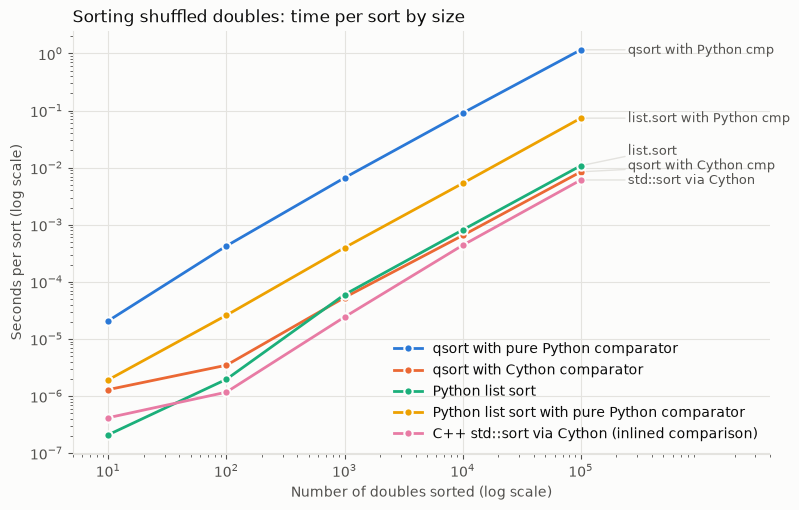

In [11]:
# Time per sort of shuffled doubles for growing sizes:
# a table in the console, then a log-log plot
import time
from functools import cmp_to_key
import matplotlib.pyplot as plt

def compare_doubles(left, right):
    return -1 if left < right else (1 if right < left else 0)

def list_sort_with_python_cmp(data):
    # Python 3 list.sort() has no cmp argument, cmp_to_key turns the comparator into a key
    data.sort(key=cmp_to_key(compare_doubles))

experiments = [  # (legend label, short label, in-place sort function); colors follow this order
    ('qsort with pure Python comparator', 'qsort with Python cmp', qsort_doubles_py),
    ('qsort with Cython comparator', 'qsort with Cython cmp', qsort_doubles_cy),
    ('Python list sort', 'list.sort', list.sort),
    ('Python list sort with pure Python comparator', 'list.sort with Python cmp', list_sort_with_python_cmp),
    ('C++ std::sort via Cython (inlined comparison)', 'std::sort via Cython', std_sort_doubles),
]
list_sorts = {list.sort, list_sort_with_python_cmp}  # these sort a Python list, the others a ctypes array
exponents = range(1, 6)  # sort 10**k shuffled doubles

seconds_per_sort = {short: [] for _, short, _ in experiments}
for k in exponents:
    shuffled = prepare_shuffled_doubles(10**k)
    expected = sorted(shuffled)
    runs = 1 if k >= 6 else 3  # best of 3, but a single run at 10**6 where the Python comparator takes seconds
    for label, short, sort in experiments:
        best = float('inf')
        for _ in range(runs):
            # Sorting is in place, so every run gets a fresh shuffled copy made outside the timed part
            data = list(shuffled) if sort in list_sorts else (c_double * len(shuffled))(*shuffled)
            start = time.perf_counter()
            sort(data)
            best = min(best, time.perf_counter() - start)
        assert list(data) == expected, f'{short} did not sort 10**{k} doubles'
        seconds_per_sort[short].append(best)

print('Milliseconds per sort')
print(f'{"doubles":>10s}\t' + '\t'.join(f'{short:>25s}' for _, short, _ in experiments))
for i, k in enumerate(exponents):
    print(f'{f"10**{k}":>10s}\t' + '\t'.join(f'{seconds_per_sort[short][i] * 1e3:25.3f}' for _, short, _ in experiments))

for exp in (0, -1):
    python_time = seconds_per_sort['qsort with Python cmp'][exp]
    print(f'\nSpeedup over the Python comparator at 10**{exponents[exp]}: '
          + ', '.join(f'{short} x{python_time / seconds_per_sort[short][exp]:.1f}' for _, short, _ in experiments[1:]))

# Categorical slots 1-5 of the reference palette, validated for adjacent lines on a light surface
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
surface, text_primary, text_secondary, grid = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

sizes = [10**k for k in exponents]
fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=surface)
ax.set_facecolor(surface)
for (label, short, _), color in zip(experiments, colors):
    ax.plot(sizes, seconds_per_sort[short], color=color, linewidth=2, marker='o', markersize=6,
            markeredgecolor=surface, markeredgewidth=1.5, label=label)

# Direct labels at the line ends, nudged apart where lines end close together
label_y = []
for value, short in sorted((seconds_per_sort[short][-1], short) for _, short, _ in experiments):
    y = max(value, label_y[-1] * 1.8) if label_y else value
    label_y.append(y)
    ax.annotate(short, xy=(sizes[-1], value), xytext=(sizes[-1] * 2.5, y), color=text_secondary, fontsize=9,
                va='center', arrowprops=dict(arrowstyle='-', color=grid, linewidth=1, shrinkA=0, shrinkB=4))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(sizes[0] / 2, sizes[-1] * 40)
ax.set_xticks(sizes)  # only the measured sizes, not the space reserved for the line labels
ax.set_xlabel('Number of doubles sorted (log scale)', color=text_secondary)
ax.set_ylabel('Seconds per sort (log scale)', color=text_secondary)
ax.set_title('Sorting shuffled doubles: time per sort by size', color=text_primary, loc='left')
ax.grid(True, which='major', color=grid, linewidth=0.8)
ax.tick_params(colors=text_secondary, which='both')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color(grid)
ax.legend(loc='lower right', frameon=False, labelcolor=text_primary)  # the lines rise to the upper right
plt.show()